In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import tensorflow as tf
import os

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
import os

DATASET_PATH = (
    "/kaggle/input/datasets/omrathod2003/"
    "140-most-popular-crops-image-dataset"
)

print("Dataset exists:", os.path.exists(DATASET_PATH))

if os.path.exists(DATASET_PATH):
    print("\nTop-level folders:")

    for item in os.listdir(DATASET_PATH):
        path = os.path.join(DATASET_PATH, item)

        if os.path.isdir(path):
            print("Folder:", item)
        else:
            print("File:", item)

Dataset exists: True

Top-level folders:
File: 140_crops_list.txt
Folder: BGR_224x224
Folder: GRAY_224x224
Folder: RGB_224x224
Folder: Raw


In [3]:
import os

IMAGE_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
)

split_names = {
    "train", "training",
    "valid", "validation", "val",
    "test", "testing"
}

found_splits = {}

for root, dirs, files in os.walk(DATASET_PATH):
    folder_name = os.path.basename(root).lower()

    if folder_name in split_names:
        found_splits.setdefault(folder_name, []).append(root)

print("FOUND DATA SPLITS")

for split, paths in found_splits.items():
    print(f"\n{split.upper()}")

    for path in paths:
        print(path)

FOUND DATA SPLITS

TEST
/kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/test
/kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/GRAY_224x224/GRAY_224x224/test
/kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/RGB_224x224/RGB_224x224/test

TRAIN
/kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/train
/kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/GRAY_224x224/GRAY_224x224/train
/kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/RGB_224x224/RGB_224x224/train

VAL
/kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/val
/kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/GRAY_224x224/GRAY_224x224/val
/kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/RGB_224x224/RGB_224x224/val


In [4]:
def count_images_in_folder(folder):
    count = 0

    for root, dirs, files in os.walk(folder):
        count += sum(
            1 for file in files
            if file.lower().endswith(IMAGE_EXTENSIONS)
        )

    return count


for split, paths in found_splits.items():
    print(f"\n{split.upper()}")

    for path in paths:
        print(
            "Path:", path,
            "| Images:", count_images_in_folder(path)
        )


TEST
Path: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/test | Images: 6627
Path: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/GRAY_224x224/GRAY_224x224/test | Images: 6627
Path: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/RGB_224x224/RGB_224x224/test | Images: 6627

TRAIN
Path: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/train | Images: 27639
Path: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/GRAY_224x224/GRAY_224x224/train | Images: 27639
Path: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/RGB_224x224/RGB_224x224/train | Images: 27639

VAL
Path: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/val | Images: 6422
Path: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/GRAY_224x224/GRAY_224x224/val | I

In [6]:
import os
import pandas as pd
import numpy as np

SEED = 42
TRAIN_PER_CLASS = 150
VAL_PER_CLASS = 30

rng = np.random.default_rng(SEED)

def collect_class_images(split_path):
    records = []

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if not os.path.isdir(class_path):
            continue

        for file in os.listdir(class_path):
            if file.lower().endswith(IMAGE_EXTENSIONS):
                records.append({
                    "filepath": os.path.join(class_path, file),
                    "label": class_name
                })

    return pd.DataFrame(records)


def sample_per_class(frame, max_images):
    sampled_groups = []

    for label, group in frame.groupby("label"):
        n = min(max_images, len(group))

        indices = rng.choice(
            group.index.to_numpy(),
            size=n,
            replace=False
        )

        sampled_groups.append(frame.loc[indices])

    return (
        pd.concat(sampled_groups)
        .sample(frac=1, random_state=SEED)
        .reset_index(drop=True)
    )


print("Sampling functions ready.")

Sampling functions ready.


In [7]:
import os
import time
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, Model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 5

tf.keras.utils.set_random_seed(SEED)

DATASET_PATH = (
    "/kaggle/input/datasets/omrathod2003/"
    "140-most-popular-crops-image-dataset"
)

OUTPUT_PATH = "/kaggle/working"

IMAGE_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Dataset exists:", os.path.exists(DATASET_PATH))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Dataset exists: True


In [8]:
split_names = {
    "train", "training",
    "valid", "validation", "val",
    "test", "testing"
}

found_splits = {}

for root, dirs, files in os.walk(DATASET_PATH):
    name = os.path.basename(root).lower()

    if name in split_names:
        found_splits.setdefault(name, []).append(root)

print("Detected splits:")

for split, paths in found_splits.items():
    for path in paths:
        print(split, "->", path)

Detected splits:
test -> /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/test
test -> /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/GRAY_224x224/GRAY_224x224/test
test -> /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/RGB_224x224/RGB_224x224/test
train -> /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/train
train -> /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/GRAY_224x224/GRAY_224x224/train
train -> /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/RGB_224x224/RGB_224x224/train
val -> /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/val
val -> /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/GRAY_224x224/GRAY_224x224/val
val -> /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/RGB_224x224/RGB

In [17]:
def count_images(folder):
    count = 0

    for root, dirs, files in os.walk(folder):
        count += sum(
            f.lower().endswith(IMAGE_EXTENSIONS)
            for f in files
        )

    return count


def choose_split(candidates):
    # Prefer the largest matching split directory.
    candidates = sorted(
        candidates,
        key=count_images,
        reverse=True
    )

    return candidates[0] if candidates else None


train_candidates = (
    found_splits.get("train", [])
    + found_splits.get("training", [])
)

val_candidates = (
    found_splits.get("valid", [])
    + found_splits.get("validation", [])
    + found_splits.get("val", [])
)

test_candidates = (
    found_splits.get("test", [])
    + found_splits.get("testing", [])
)

TRAIN_PATH = choose_split(train_candidates)
VAL_PATH = choose_split(val_candidates)
TEST_PATH = choose_split(test_candidates)

print("TRAIN:", TRAIN_PATH)
print("VALIDATION:", VAL_PATH)
print("TEST:", TEST_PATH)

if TRAIN_PATH is None:
    raise FileNotFoundError(
        "Training folder not found. Inspect the detected split paths."
    )

if VAL_PATH is None:
    raise FileNotFoundError(
        "Validation folder not found. Check the dataset structure. "
        "Do not randomly split the test set into training data."
    )

if TEST_PATH is None:
    raise FileNotFoundError(
        "Test folder not found. Inspect the dataset structure."
    )

TRAIN: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/train
VALIDATION: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/val
TEST: /kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset/BGR_224x224/BGR_224x224/test


In [18]:
def collect_images(split_path):
    records = []

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if not os.path.isdir(class_path):
            continue

        for file in os.listdir(class_path):
            if file.lower().endswith(IMAGE_EXTENSIONS):
                records.append({
                    "filepath": os.path.join(class_path, file),
                    "label": class_name
                })

    return pd.DataFrame(records)


train_all = collect_images(TRAIN_PATH)
val_all = collect_images(VAL_PATH)
test_df = collect_images(TEST_PATH)

print("Original training images:", len(train_all))
print("Original validation images:", len(val_all))
print("Original test images:", len(test_df))

# Use the classes present in the training split.
class_names = sorted(train_all["label"].unique())

print("Training classes:", len(class_names))

if len(class_names) != 140:
    print("WARNING: Expected 140 classes; inspect the folder structure.")

# Retain only classes represented in all three splits.
common_classes = (
    set(train_all["label"])
    & set(val_all["label"])
    & set(test_df["label"])
)

if len(common_classes) != len(class_names):
    print("WARNING: Some classes are missing from one or more splits.")

class_names = sorted(common_classes)

train_all = train_all[train_all["label"].isin(class_names)]
val_all = val_all[val_all["label"].isin(class_names)]
test_df = test_df[test_df["label"].isin(class_names)]

rng = np.random.default_rng(SEED)


def sample_per_class(frame, max_images):
    samples = []

    for label, group in frame.groupby("label"):
        n = min(max_images, len(group))

        indices = rng.choice(
            group.index.to_numpy(),
            size=n,
            replace=False
        )

        samples.append(group.loc[indices])

    if not samples:
        raise ValueError("No class images were found.")

    return (
        pd.concat(samples)
        .sample(frac=1, random_state=SEED)
        .reset_index(drop=True)
    )


train_df = sample_per_class(train_all, 150)
val_df = sample_per_class(val_all, 30)

# Use up to 100 images per class for preliminary evaluation.
# Increase this or evaluate the full test set for final reporting.
test_eval_df = sample_per_class(test_df, 100)

class_names = sorted(train_df["label"].unique())
label_to_id = {name: i for i, name in enumerate(class_names)}
NUM_CLASSES = len(class_names)

print("\nFinal dataset:")
print("Classes:", NUM_CLASSES)
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test evaluation:", len(test_eval_df))

print("Training classes:", train_df["label"].nunique())
print("Validation classes:", val_df["label"].nunique())
print("Test classes:", test_eval_df["label"].nunique())

Original training images: 27639
Original validation images: 6422
Original test images: 6627
Training classes: 139

Final dataset:
Classes: 139
Training: 20648
Validation: 4144
Test evaluation: 6558
Training classes: 139
Validation classes: 139
Test classes: 139


In [19]:
AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(frame, model_name, training=False):
    paths = frame["filepath"].to_numpy()

    labels = frame["label"].map(label_to_id).to_numpy(
        dtype=np.int32
    )

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)

        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(
            image,
            (IMG_SIZE, IMG_SIZE)
        )

        image = tf.cast(image, tf.float32)

        if model_name == "ResNet50":
            image = tf.keras.applications.resnet50.preprocess_input(
                image
            )
        else:
            image = tf.keras.applications.mobilenet_v2.preprocess_input(
                image
            )

        return image, label

    if training:
        ds = ds.shuffle(
            min(len(frame), 5000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return (
        ds.map(load_image, num_parallel_calls=AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )


print("Data pipeline ready.")

Data pipeline ready.


In [20]:
def build_model(model_name):
    if model_name == "ResNet50":
        base_model = tf.keras.applications.ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(IMG_SIZE, IMG_SIZE, 3)
        )

    elif model_name == "MobileNetV2":
        base_model = tf.keras.applications.MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=(IMG_SIZE, IMG_SIZE, 3)
        )

    else:
        raise ValueError("Unknown model name.")

    base_model.trainable = False

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.05)(x)

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        dtype="float32"
    )(x)

    model = Model(inputs, outputs, name=model_name)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


print("Model-building function ready.")

Model-building function ready.


In [22]:
results = []

for model_name in ["ResNet50", "MobileNetV2"]:

    print("\n" + "=" * 60)
    print("TRAINING:", model_name)
    print("=" * 60)

    tf.keras.backend.clear_session()
    gc.collect()

    train_ds = make_dataset(
        train_df, model_name, training=True
    )

    val_ds = make_dataset(
        val_df, model_name
    )

    test_ds = make_dataset(
        test_eval_df, model_name
    )

    model = build_model(model_name)

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=f"{OUTPUT_PATH}/{model_name}_best.keras",
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=1,
            min_lr=1e-6
        )
    ]

    start_time = time.time()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

    training_time = time.time() - start_time

    # Predict on the same held-out test sample.
    probabilities = model.predict(test_ds, verbose=1)

    y_true = test_eval_df["label"].map(label_to_id).to_numpy()
    y_pred = np.argmax(probabilities, axis=1)

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    try:
        y_true_binary = label_binarize(
            y_true,
            classes=np.arange(NUM_CLASSES)
        )

        auc = roc_auc_score(
            y_true_binary,
            probabilities,
            average="macro",
            multi_class="ovr"
        )

    except ValueError:
        auc = np.nan

    # Approximate inference latency per image.
    sample_images, _ = next(iter(test_ds))

    for _ in range(2):
        _ = model(sample_images, training=False)

    start_inference = time.time()

    for _ in range(10):
        _ = model(sample_images, training=False)

    inference_time = (
        (time.time() - start_inference)
        * 1000
        / (10 * int(sample_images.shape[0]))
    )

    result = {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision_macro": precision,
        "Recall_macro": recall,
        "F1_macro": f1,
        "ROC_AUC_macro": auc,
        "Parameters": model.count_params(),
        "Training_time_seconds": training_time,
        "Inference_ms_per_image": inference_time
    }

    results.append(result)

    model.save(f"{OUTPUT_PATH}/{model_name}_final.keras")

    pd.DataFrame(history.history).to_csv(
        f"{OUTPUT_PATH}/{model_name}_history.csv",
        index=False
    )

    print("\nRESULTS:", result)

    del model, train_ds, val_ds, test_ds
    gc.collect()


results_df = pd.DataFrame(results)

results_df.to_csv(
    f"{OUTPUT_PATH}/crop_model_comparison.csv",
    index=False
)

print("\nFINAL COMPARISON")
print(results_df.to_string(index=False))


TRAINING: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
646/646 ━━━━━━━━━━━━━━━━━━━━ 0s 848ms/step - accuracy: 0.1444 - loss: 4.5498
Epoch 1: val_loss improved from None to 2.90246, saving model to /kaggle/working/ResNet50_best.keras

Epoch 1: finished saving model to /kaggle/working/ResNet50_best.keras
646/646 ━━━━━━━━━━━━━━━━━━━━ 671s 1s/step - accuracy: 0.2240 - loss: 3.8855 - val_accuracy: 0.3682 - val_loss: 2.9025 - learning_rate: 0.0010
Epoch 2/5
645/646 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.3905 - loss: 2.7258
Epoch 2: val_loss improved from 2.90246 to 2.74467, saving model to /kaggle/working/ResNet50_best.keras

Epoch 2: finished saving model to /kaggle/working/ResNet50_best.keras
646/646 ━━━━━━━━━━━━━━━━━━━━ 101s 157ms/step - accuracy: 0.3879 - loss: 2.7504 - val_accuracy: 0.4298 - val_loss: 2.7447 - learning_rate: 0.0010
Epoch 3/5
645/646 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.4524 - loss: 2.3507
Epoch 3: val_loss improved from 2.

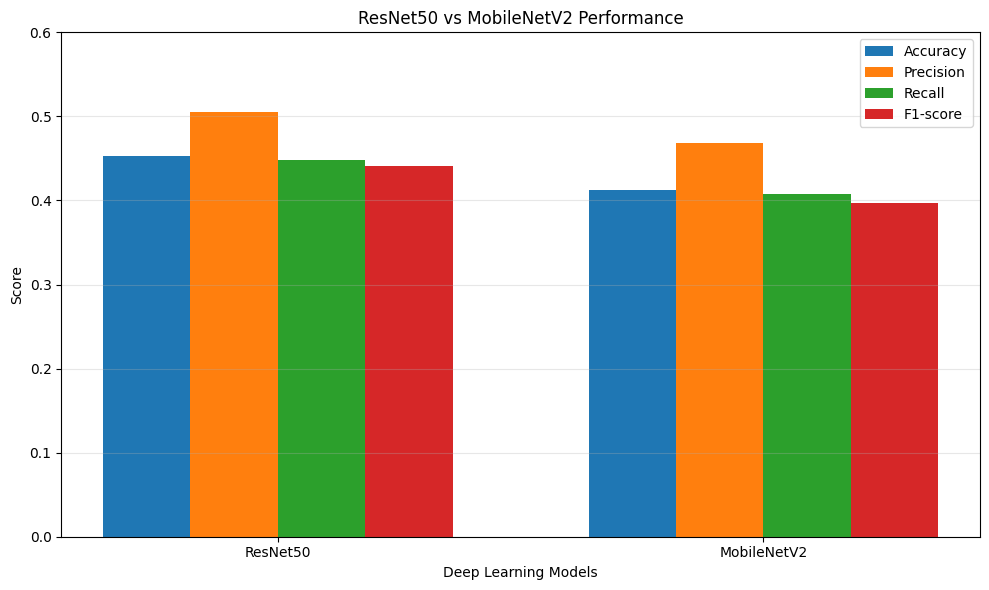

In [24]:
import matplotlib.pyplot as plt
import numpy as np

models = ['ResNet50', 'MobileNetV2']

accuracy = [0.452425, 0.412016]
precision = [0.505765, 0.468488]
recall = [0.448026, 0.407765]
f1_score = [0.440803, 0.397263]

x = np.arange(len(models))
width = 0.18

plt.figure(figsize=(10, 6))

plt.bar(x - 1.5*width, accuracy, width, label='Accuracy')
plt.bar(x - 0.5*width, precision, width, label='Precision')
plt.bar(x + 0.5*width, recall, width, label='Recall')
plt.bar(x + 1.5*width, f1_score, width, label='F1-score')

plt.title('ResNet50 vs MobileNetV2 Performance')
plt.xlabel('Deep Learning Models')
plt.ylabel('Score')
plt.xticks(x, models)
plt.ylim(0, 0.6)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

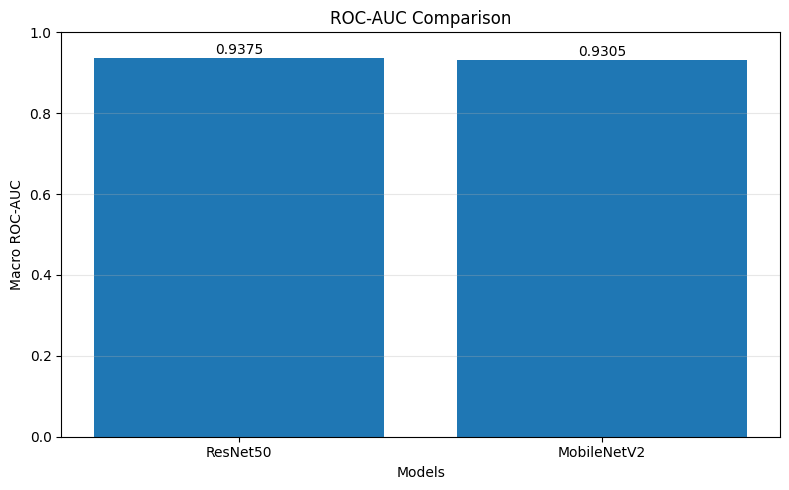

In [25]:
models = ['ResNet50', 'MobileNetV2']
roc_auc = [0.937485, 0.930521]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, roc_auc)

plt.title('ROC-AUC Comparison')
plt.xlabel('Models')
plt.ylabel('Macro ROC-AUC')
plt.ylim(0, 1.0)

for bar, value in zip(bars, roc_auc):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.01,
        f'{value:.4f}',
        ha='center'
    )

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

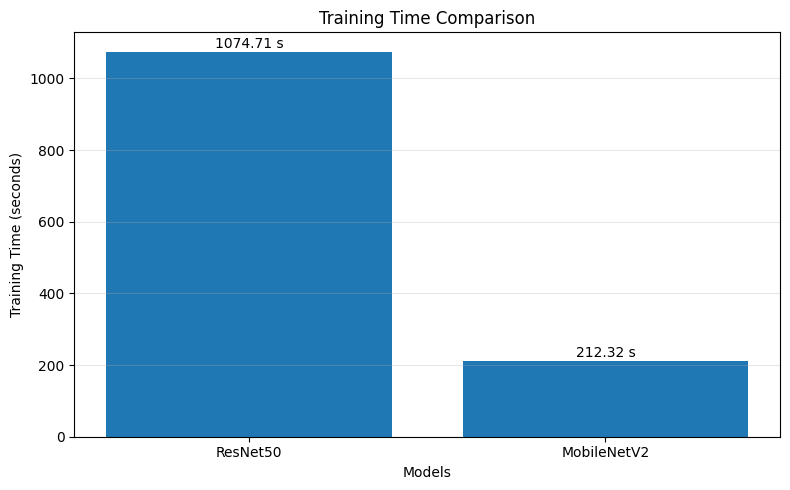

In [26]:
models = ['ResNet50', 'MobileNetV2']
training_time = [1074.71, 212.32]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, training_time)

plt.title('Training Time Comparison')
plt.xlabel('Models')
plt.ylabel('Training Time (seconds)')

for bar, value in zip(bars, training_time):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 10,
        f'{value:.2f} s',
        ha='center'
    )

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

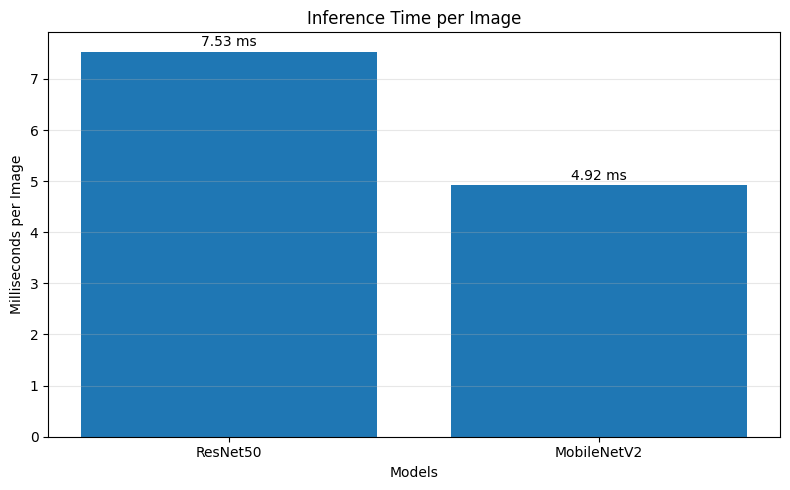

In [27]:
models = ['ResNet50', 'MobileNetV2']
inference_time = [7.533956, 4.921741]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, inference_time)

plt.title('Inference Time per Image')
plt.xlabel('Models')
plt.ylabel('Milliseconds per Image')

for bar, value in zip(bars, inference_time):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        f'{value:.2f} ms',
        ha='center'
    )

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Total images found: 160565


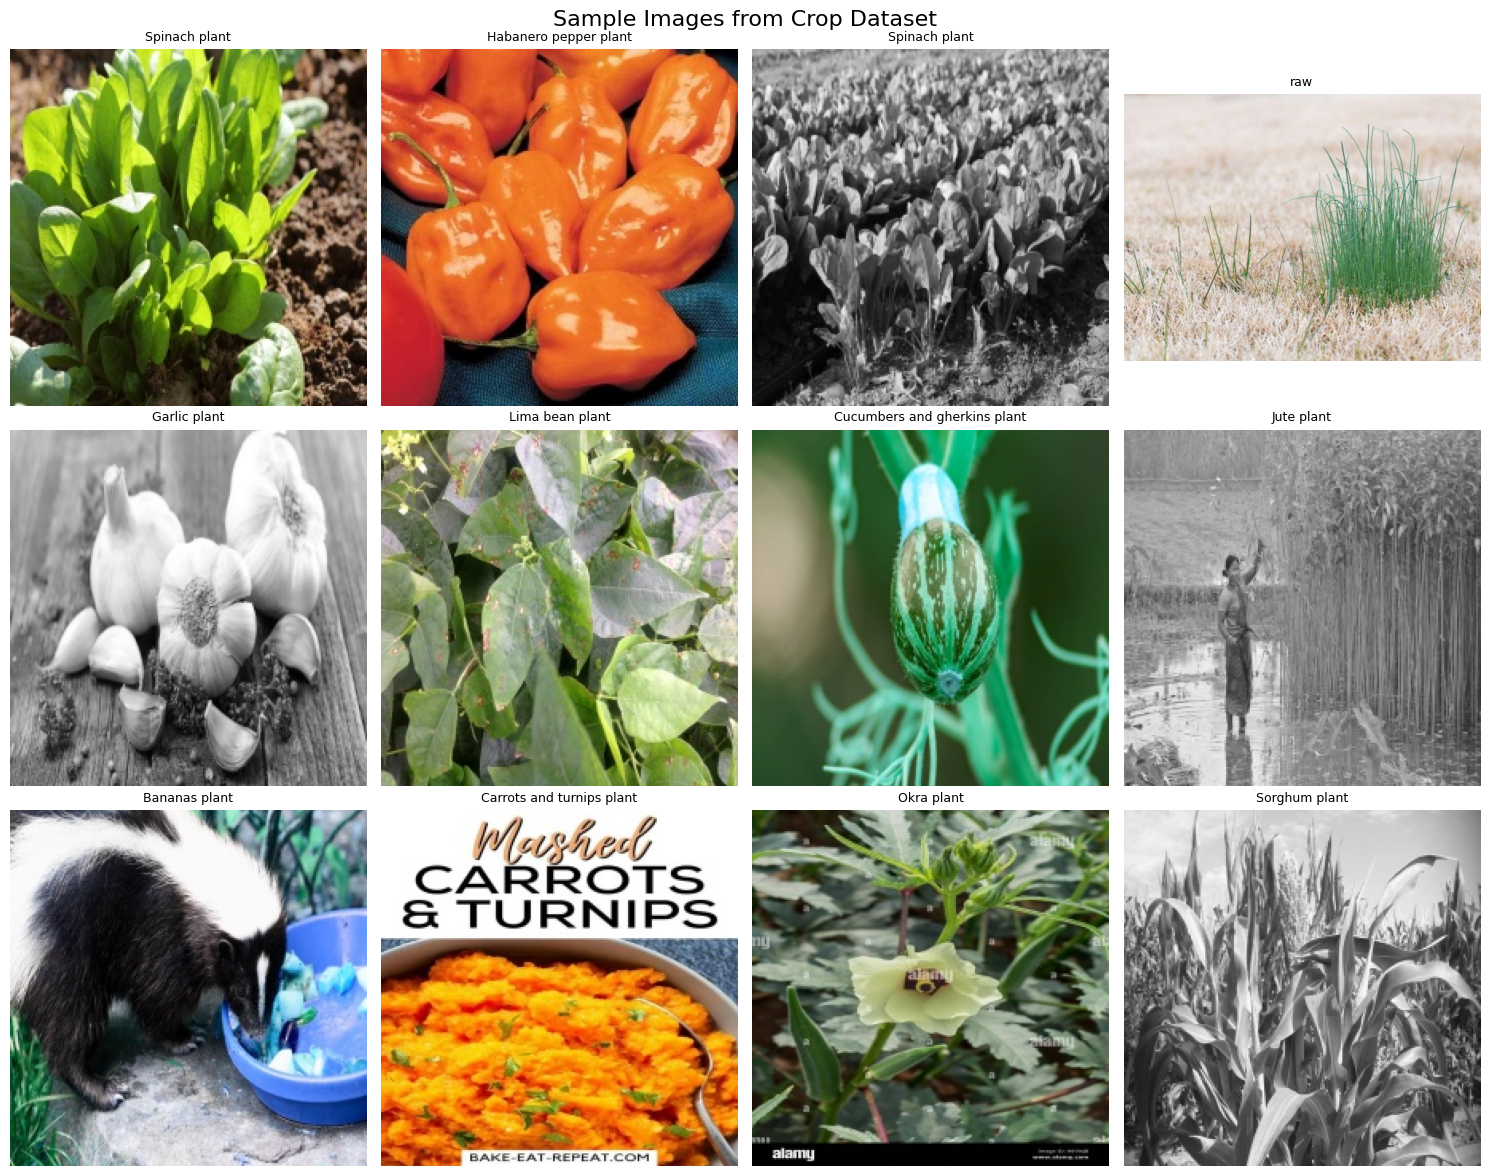

In [28]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Dataset path
DATASET_PATH = "/kaggle/input/datasets/omrathod2003/140-most-popular-crops-image-dataset"

# Find all image files
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
image_files = []

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, file))

print("Total images found:", len(image_files))

# Select 12 random images
sample_images = random.sample(
    image_files, min(12, len(image_files))
)

# Display images
plt.figure(figsize=(15, 12))

for i, image_path in enumerate(sample_images):
    try:
        img = Image.open(image_path).convert("RGB")

        # Use the parent folder as the crop label
        crop_name = os.path.basename(os.path.dirname(image_path))

        plt.subplot(3, 4, i + 1)
        plt.imshow(img)
        plt.title(crop_name, fontsize=9)
        plt.axis("off")

    except Exception as e:
        print("Could not open:", image_path)

plt.suptitle("Sample Images from Crop Dataset", fontsize=16)
plt.tight_layout()
plt.show()